# 00 — Create your first baseline

**First prepare your dataset with [00_prepare_account_sample.ipynb](00_prepare_account_sample.ipynb), then start here.** You will train the generator, generate one complete synthetic dataset, and evaluate it against the real reference.

This notebook needs preprocessed Berka tables, not existing models or experiment results. It uses the toolkit's training/synthesis functions through shared helpers. The original workflow files remain references.

1. Install the declared environment from the repository terminal: `uv sync --locked --group tabular-data --inexact`.
2. Select the project's `.venv` notebook kernel. Run [00_prepare_account_sample.ipynb](00_prepare_account_sample.ipynb) to create the separate account-sampled dataset (500 accounts, seed 42 by default).
3. Preview this notebook with `RUN_NEW_TRIALS = False`. When ready for GPU work, change it to `True` and rerun cells in order.
4. After a successful baseline evaluation, open [guidance_strength_tuning.ipynb](sweeps/guidance_strength_tuning.ipynb).

You execute the notebooks yourself. The baseline completed on 2026-11-12; recorded stage durations total about **5 min 27 s**, excluding evaluation. See the completed run record and conclusion below.

All 8 tables remain in the generator. The new dataset retains every raw transaction for the selected accounts. The baseline now reports full-table quality and overdraft/transaction quality together. Edit [dataset_settings.py](../dataset_settings.py) to select another input/output dataset path before running. No original synthesized files are overwritten.


In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image
from IPython.display import display as show


ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/transaction-evaluation-matplotlib")
MULTI_TABLE = ROOT / "implementations/tabular_data/multi_table"

from implementations.tabular_data.multi_table.evaluation.transaction_evaluation import evaluate_saved_runs
from implementations.tabular_data.multi_table.experiments.dataset_settings import DATA_DIR as DEFAULT_DATA_DIR
from implementations.tabular_data.multi_table.experiments.tuning import (
    DEFAULT_EXPERIMENT_ROOT,
    DEFAULT_REPORT_ROOT,
    base_config,
    completed_runs,
    preview_trials,
    run_trials,
)


## 1. Baseline settings and input check

The baseline copies repository settings, with the same **70/20/10 internal split** for diffusion and guidance classifiers because they fit their preprocessing separately. Guidance is 1, training/sampling seeds are 42, and sample scale is 1 (full reference size).

Use the same input tables and experiment root across subsequent notebooks. A dedicated `transaction_tuning_from_scratch` directory keeps this workflow independent of older artifacts. Preprocessing already provides all required input tables; separate original training/synthesis notebook runs are unnecessary.

In [2]:
RUN_NEW_TRIALS = False  # Change to True yourself when ready for GPU training.
# Edit dataset_settings.py once to switch every notebook, or override here.
DATA_DIR = DEFAULT_DATA_DIR
EXPERIMENT_ROOT = DEFAULT_EXPERIMENT_ROOT
OUTPUT_ROOT = DEFAULT_REPORT_ROOT
BASE = base_config(fresh_training=True)
TRIALS = [BASE]  # One configuration, training seed 42 and sampling seed 42.

import json


meta_path = DATA_DIR / "dataset_meta.json"
if not meta_path.is_file():
    raise FileNotFoundError("Run 00_prepare_account_sample.ipynb first, or select an existing processed DATA_DIR in dataset_settings.py.")
meta = json.loads(meta_path.read_text())
required = [meta_path, DATA_DIR / "preprocess_meta.json"]
for table in meta["tables"]:
    required += [DATA_DIR / f"{table}.csv", DATA_DIR / f"{table}_domain.json"]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError(f"Missing preprocessed inputs: {missing}")
print(f"Inputs ready: {len(meta['tables'])} tables. No saved experiments or models are required.")

print(f"Selected processed dataset: {DATA_DIR}")


Inputs ready: 8 tables. No saved experiments or models are required.
Selected processed dataset: /home/armoso/repo/vector-bootcamp-synthetic-data/implementations/tabular_data/multi_table/data/berka_accounts_500_seed42


/home/armoso/repo/vector-bootcamp-synthetic-data/.venv/lib64/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 2. Preview the work

One baseline configuration trains models for every parent/table relation, then generates a full dataset. This is the controlled reference for later parameter changes. A preview does not train models or create synthetic data.

In [3]:
PLAN = preview_trials(TRIALS)
show(PLAN.drop(columns="config"))
show(pd.json_normalize(BASE, sep="."))
print("First execution: clustering, diffusion training, guidance-classifier training, and generation.")
print("Later identical executions reuse verified completed stages.")


,cluster,diffusion,model,sample,training_seed,sampling_seed,guidance,clusters
0,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,013d0db4bc897faae5dc,42,42,1.0,50


,training_seed,sampling_seed,diffusion_config.d_layers,diffusion_config.dropout,diffusion_config.num_timesteps,diffusion_config.model_type,diffusion_config.iterations,diffusion_config.batch_size,diffusion_config.lr,diffusion_config.gaussian_loss_type,...,classifier_config.batch_size,classifier_config.iterations,classifier_config.data_split_ratios,sampling_config.batch_size,sampling_config.classifier_scale,sampling_config.sample_scale,matching_config.num_matching_clusters,matching_config.matching_batch_size,matching_config.unique_matching,matching_config.no_matching
0,42,42,"[512, 1024, 1024, 1024, 1024, 512]",0.0,500,mlp,5000,256,0.0006,mse,...,256,5000,"[0.7, 0.2, 0.1]",8192,1.0,1.0,1,1000,True,False


First execution: clustering, diffusion training, guidance-classifier training, and generation.
Later identical executions reuse verified completed stages.


## 3. Create the baseline on GPU

Enable `RUN_NEW_TRIALS` in step 1 yourself when ready. Keep the default seeds and model settings for the first baseline. Changing those settings requires using the same revised baseline in subsequent notebooks.

Run one generating notebook at a time. Completed stages are reused; an interrupted stage records its failure and is not treated as complete. Inspect `status.json` before retrying with a fresh experiment root.

In [4]:
NEW_RUN_DIRS = []
if RUN_NEW_TRIALS:
    EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)
    PLAN.drop(columns="config").to_csv(EXPERIMENT_ROOT / "plan_baseline.csv", index=False)
    NEW_RUN_DIRS = run_trials(TRIALS, DATA_DIR, EXPERIMENT_ROOT, device="cuda")
    show(pd.DataFrame({"saved_baseline": [str(path) for path in NEW_RUN_DIRS]}))
else:
    print("Preview only. To create the first baseline, set RUN_NEW_TRIALS = True and rerun in order on a GPU.")


Preview only. To create the first baseline, set RUN_NEW_TRIALS = True and rerun in order on a GPU.


## 4. Evaluate the baseline on CPU

One random forest learns current negative-balance detection from real transactions. Separate real accounts provide its detector test set; the same detector evaluates generated transactions. Balance and IDs do not enter the predictors.

The report includes overdraft transfer, event counts/prevalence and uncertainty, transaction distributions, overdraft-only patterns, account counts, key integrity, and dates aligned to their original epochs. This is an exploratory transfer study; internal generator splits do not establish an independent relational outer holdout.

The full-table view covers distributions and missing/unknown values in all 8 tables, PK/FK integrity and child counts on all 8 edges, within/cross-table mixed correlations, and client–account relationships joined through `disp`. External counterparty identifiers are excluded from numerical quality scores. Tables are weighted equally in the marginal summaries.

Evaluating e2cf71fc9b2cb2bdcc74


,average_precision,average_precision_low,average_precision_high,standardized_ap,overdraft_prevalence,transaction_ks,transaction_tvd,overdraft_numerical_ks,synthetic_transaction_before_account_rate
dataset,,,,,,,,,
real_test,0.2422,0.0005,0.3606,0.2422,0.0017,NaN,NaN,NaN,NaN
e2cf71fc9b2cb2bdcc74,0.0161,0.0144,0.0183,0.0056,0.0048,0.056,0.0229,0.7073,0.2052


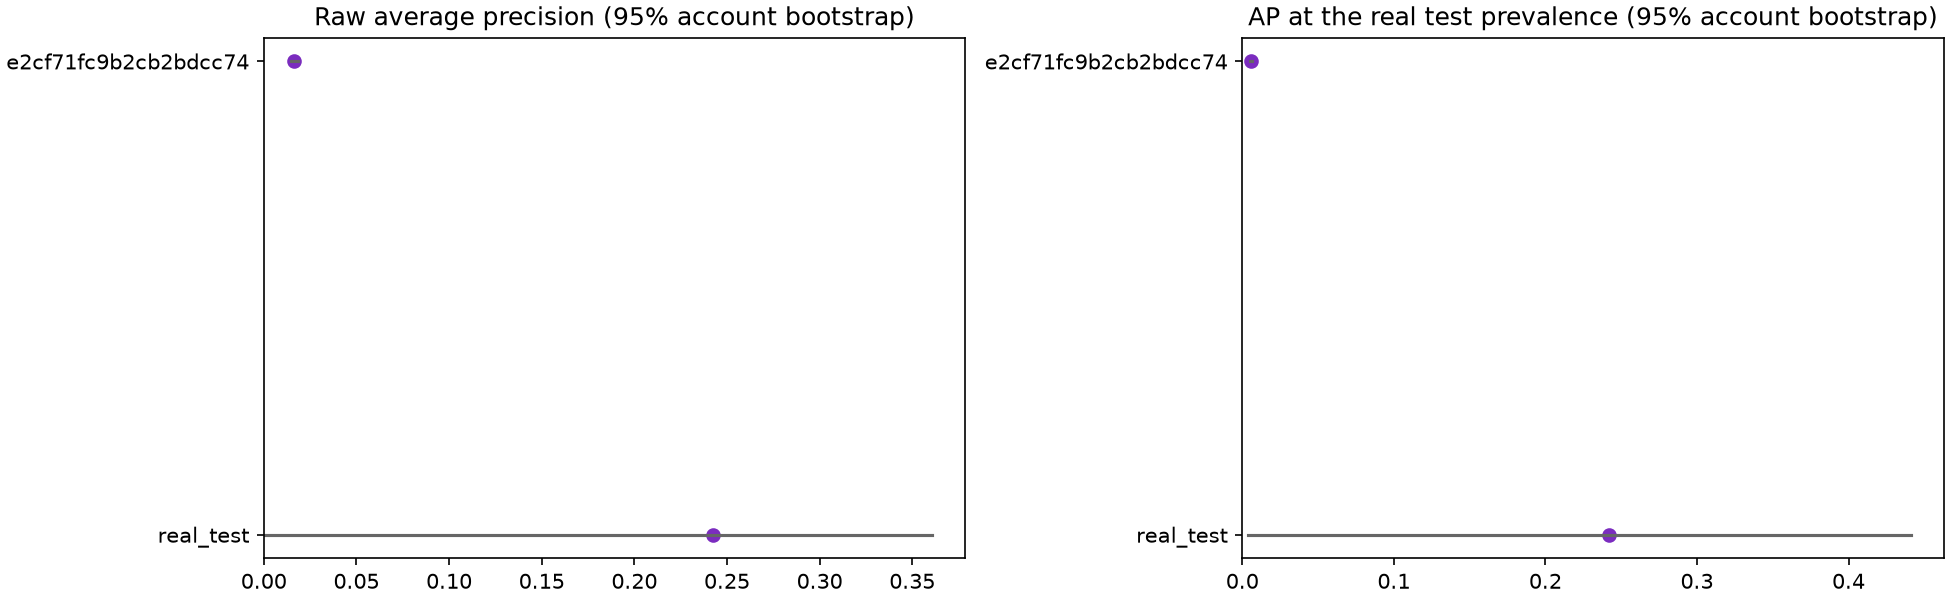

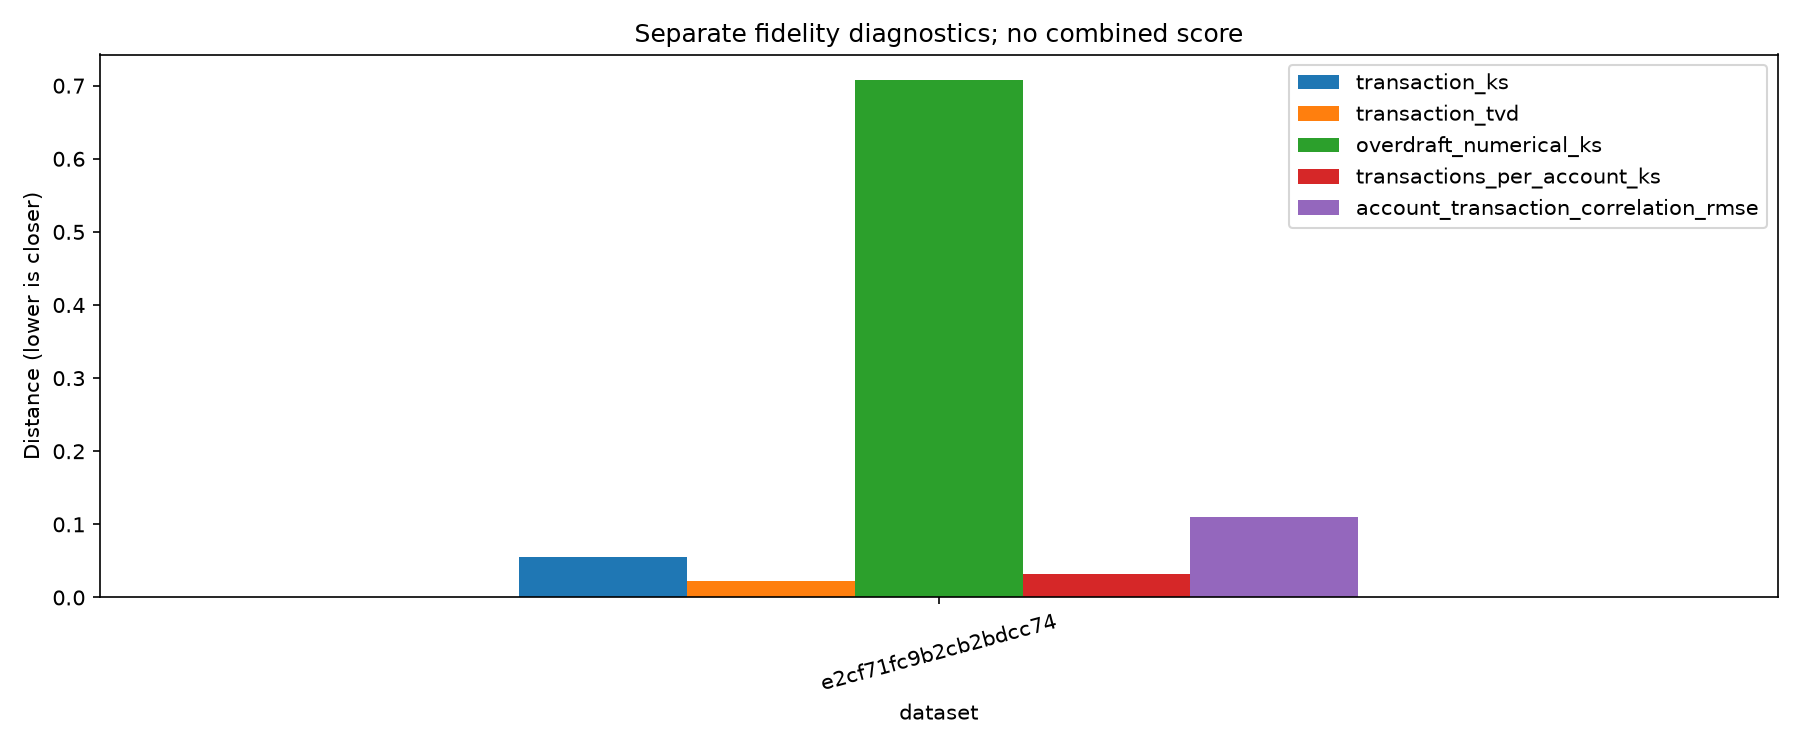

Baseline evaluated. Detailed report: /home/armoso/repo/vector-bootcamp-synthetic-data/implementations/tabular_data/multi_table/results/experiments/transaction_overdraft_from_scratch/3e9f16a5ee895f54
Full multi-table quality — separate from overdraft transfer:


,all_table_count,all_edge_count,all_table_numerical_ks,all_table_categorical_tvd,all_cardinality_ks,all_relationship_correlation_rmse,all_min_fk_valid_rate,all_min_pk_unique_rate,multi_parent_correlation_rmse,multi_parent_joint_categorical_tvd,all_undefined_distribution_columns,all_undefined_correlation_pairs
dataset,,,,,,,,,,,,
e2cf71fc9b2cb2bdcc74,8.0,8.0,0.111,0.1111,0.0867,NaN,1.0,1.0,0.0445,0.1888,0.0,2.0


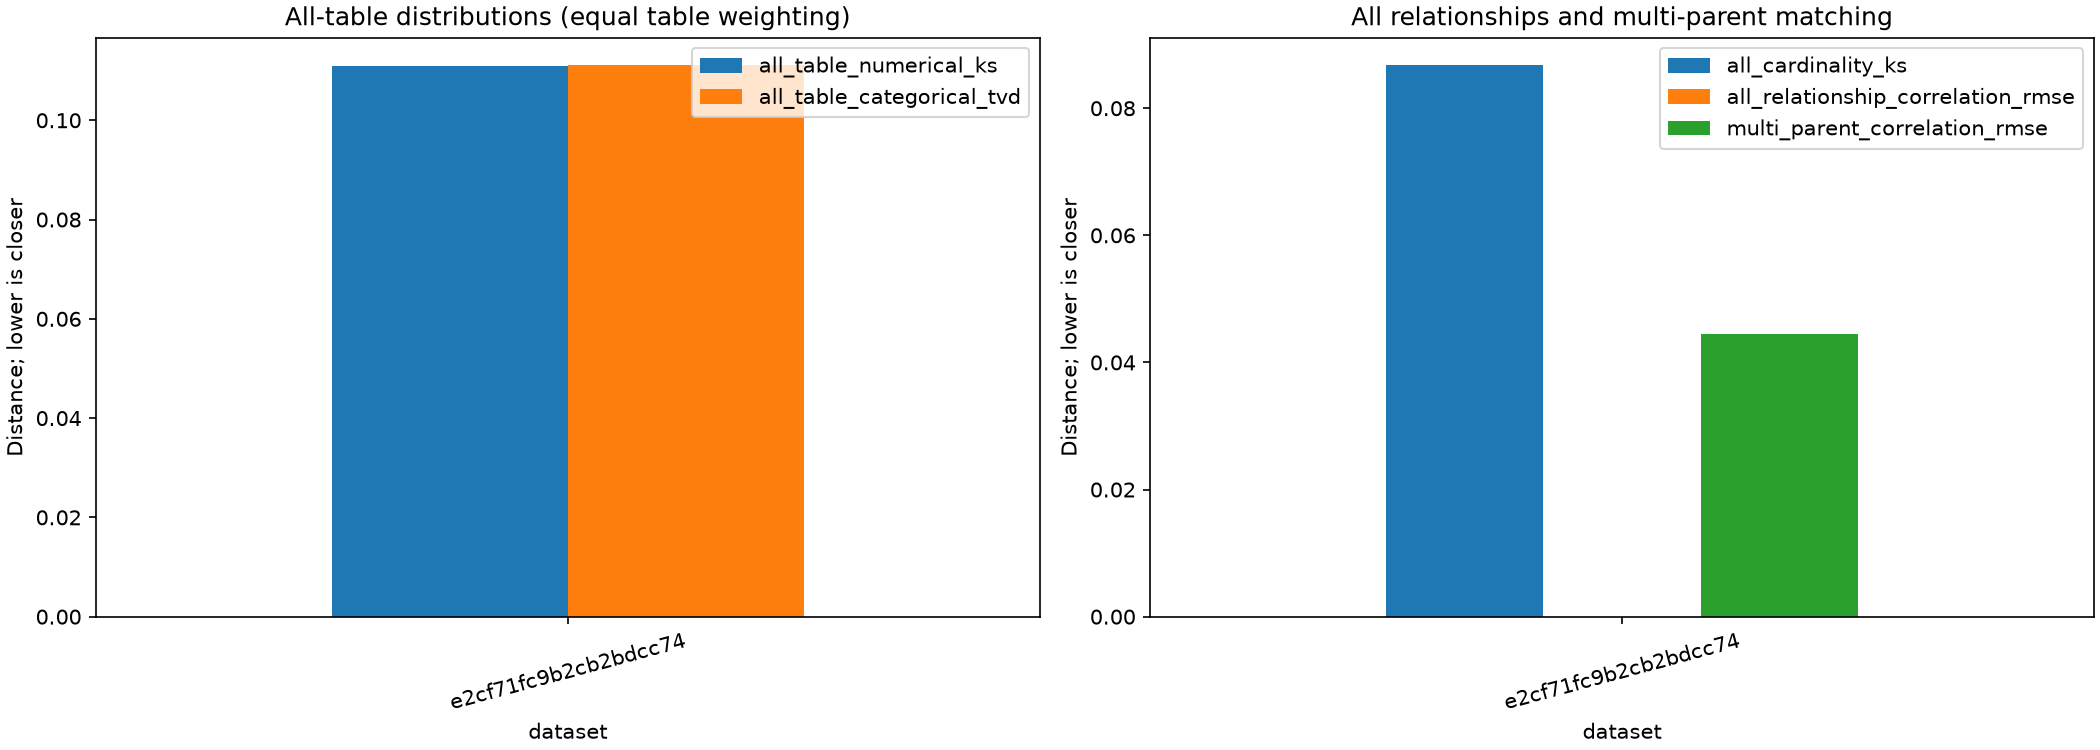

In [5]:
RUN_DIRS = completed_runs(DATA_DIR, EXPERIMENT_ROOT, configs=TRIALS) if DATA_DIR.is_dir() else []
comparison = None
REPORT_DIR = None
if RUN_DIRS:
    comparison, REPORT_DIR = evaluate_saved_runs(DATA_DIR, RUN_DIRS, OUTPUT_ROOT, bootstrap_repetitions=200)
    TRANSFER_AND_QUALITY = [
        "average_precision", "average_precision_low", "average_precision_high",
        "standardized_ap", "overdraft_prevalence", "transaction_ks", "transaction_tvd",
        "overdraft_numerical_ks", "synthetic_transaction_before_account_rate",
    ]
    show(comparison[TRANSFER_AND_QUALITY].round(4))
    show(Image(filename=str(REPORT_DIR / "transfer_intervals.png")))
    show(Image(filename=str(REPORT_DIR / "quality_comparison.png")))
    print(f"Baseline evaluated. Detailed report: {REPORT_DIR}")
else:
    print("No baseline has been generated yet. Complete step 3 before evaluating or tuning.")

if comparison is not None:
    FULL_TABLE_COLUMNS = [
        "all_table_count", "all_edge_count", "all_table_numerical_ks", "all_table_categorical_tvd",
        "all_cardinality_ks", "all_relationship_correlation_rmse", "all_min_fk_valid_rate",
        "all_min_pk_unique_rate", "multi_parent_correlation_rmse", "multi_parent_joint_categorical_tvd",
        "all_undefined_distribution_columns", "all_undefined_correlation_pairs",
    ]
    print("Full multi-table quality — separate from overdraft transfer:")
    show(comparison.loc[comparison.index != "real_test", FULL_TABLE_COLUMNS].round(4))
    show(Image(filename=str(REPORT_DIR / "multi_table_quality.png")))


## 5. Completed baseline record — 2026-11-12

**Status:** training, synthesis/matching, and evaluation completed successfully by the user. This is the reference for subsequent experiments, not a selected best configuration. It supersedes the 2026-10-29 record: the updated tuning runner (sampling batch 200 → 8,192) changes every stage fingerprint, so all models were retrained. The two records are not a controlled comparison.

- **Input:** `berka_accounts_500_seed42`: 500 accounts, all 8 linked tables, 117,560 real transactions, and 247 overdraft rows across 28 accounts.
- **Saved run:** `e2cf71fc9b2cb2bdcc74`; [resolved configuration](../../results/experiments/transaction_tuning_from_scratch/samples/e2cf71fc9b2cb2bdcc74/config.yaml) and [completed stage status](../../results/experiments/transaction_tuning_from_scratch/samples/e2cf71fc9b2cb2bdcc74/status.json).
- **Settings:** guidance **1.0**; training/sampling seeds **42/42**; **50** K-means + GMM clusters, parent scale **1.0**; 5,000 diffusion and classifier updates, 500 diffusion timesteps, aligned **70/20/10** internal splits, sampling batch **8,192**, and full sample scale **1.0**.
- **Recorded stage durations:** clustering **12.2 s**; diffusion **103.6 s**; guidance-classifier stage **165.1 s**; synthesis/matching/saving **45.8 s**. Total **5 min 27 s**, excluding evaluation and work outside these stage timers. Device recorded as CUDA.

The overdraft detector uses a separate **80/20 account split**: 400 training accounts / 94,313 transactions / 208 overdrafts; 100 test accounts / 23,247 transactions / 39 overdrafts. Only **5 test accounts** contain overdrafts.

| Detector evaluation | Real account-held-out test | Synthetic baseline |
| --- | ---: | ---: |
| Accounts | 100 | 485 |
| Transactions | 23,247 | 114,244 |
| Overdraft rows | 39 | 551 |
| Overdraft prevalence | 0.1678% | 0.4823% |
| Average precision (AP) | 0.2422 | 0.0161 |
| ROC-AUC | 0.8722 | 0.7688 |

The full real cohort prevalence is **0.2101%**. At the common real-test prevalence, synthetic standardized AP is **0.00564**. With 200 account-bootstrap draws, raw AP intervals are **0.0005–0.3606** for real test (199 valid draws) and **0.0144–0.0183** for synthetic (200 valid draws); ROC-AUC intervals are **0.664–0.966** and **0.743–0.790**. The real estimate is especially uncertain because events are concentrated in only five test accounts; these intervals condition on one fitted detector and one generated dataset.

[Full comparison](../../results/experiments/transaction_overdraft_from_scratch/3e9f16a5ee895f54/comparison.csv) · [Table breakdown](../../results/experiments/transaction_overdraft_from_scratch/3e9f16a5ee895f54/e2cf71fc9b2cb2bdcc74/all_table_scores.csv) · [Relationship breakdown](../../results/experiments/transaction_overdraft_from_scratch/3e9f16a5ee895f54/e2cf71fc9b2cb2bdcc74/all_edge_scores.csv)

### Training-seed spread

The same baseline settings were retrained with training seeds 43 and 44 (sampling seed 42). Runs: `e2cf71fc9b2cb2bdcc74`, `fa627eaf5227b73e6be4`, `524edfcd0e6f14a9c5b2`. ([report](../../results/experiments/transaction_overdraft_from_scratch/b52d0d6409bd1389/comparison.csv))

| Training seed | 42 | 43 | 44 |
| --- | ---: | ---: | ---: |
| ROC-AUC | 0.769 | 0.614 | 0.653 |
| Standardized AP | 0.0056 | 0.0034 | 0.0036 |
| Overdraft prevalence | 0.48% | 0.34% | 0.29% |
| Accounts ever overdrawn | 58.1% | 51.8% | 43.9% |
| Transactions before opening | 20.5% | 23.1% | 16.1% |
| Orphan cards | 0 | 11 | 0 |

Across sampling seeds at training seed 42, ROC-AUC varies only ±0.007. Retraining moves results roughly ten times more than resampling.

## 6. Baseline conclusion

1. **The pipeline works, but valid keys do not establish realistic data.** All 8 tables and 8 relationships were evaluated; minimum PK uniqueness and FK validity are **1.0**, with no detected invalid feature values or unknown categories. Mean full-table numerical KS is **0.1110** and categorical TVD is **0.1111**. Table sizes differ: clients/dispositions are **425 vs 596** real, cards **59 vs 90**, loans **60 vs 76**, and orders **810 vs 742**. **107/485 synthetic accounts (22.1%) have no disposition and therefore no linked client**, versus none of the 500 real accounts (account→disp cardinality KS **0.2206**); FK validity cannot detect this. These are baseline discrepancies to track, not evidence of their cause.
2. **Overdraft behavior is much less faithful than overall transaction distributions.** Overall transaction KS/TVD are **0.0560/0.0229**, but overdraft-only KS/TVD rise to **0.7073/0.5816**. Synthetic overdraft prevalence is **0.4823%** versus **0.2101%** in the full real cohort, and overdrafts occur in **282/485 synthetic accounts (58.1%)** versus **28/500 real accounts (5.6%)**: they are spread across far more accounts. The low synthetic detector AP is another warning sign, although the wide real interval prevents a precise estimate of the transfer gap.
3. **Chronology and cross-table patterns need improvement.** **20.5%** of synthetic transactions precede account opening; the real rate is **0%**. District is the least faithful table (numerical KS **0.2328**, categorical TVD **0.3571**). Account→loan correlation RMSE is **0.3562**, driven mainly by account-opening vs loan date: correlation **0.958** real vs **−0.115** synthetic. Multi-parent client/account correlation RMSE is **0.0445**, with joint categorical TVD **0.1888**.
4. **Retraining noise is larger than any tuning effect.** ROC-AUC spans **0.614–0.769** across training seeds versus ±0.007 across sampling seeds, and every 2026-10-29 value falls inside the training-seed ranges. From now on, compare any setting that retrains over 3 training seeds, paired by seed.
5. **The missing dispositions come from multi-parent matching.** The toolkit's `handle_multi_parent` keeps whichever synthetic version of `disp` is smaller: client-side or account-side.
   - When the client side is smaller, as in this run, unmatched accounts lose their dispositions (107 here).
   - When the account side is smaller, as at training seed 43, clients lose theirs. Cards, which were generated from the client-side version, then point to missing dispositions (11 orphan cards) or to the wrong ones. FK checks cannot detect the wrong ones.
6. **The matching fix works (3 training seeds, paired).** At seed 43, orphan cards went from 11 to 0 and clients without a disposition from 79 to 0. Accounts without a disposition went from 107 to 60 at seed 42 (the remaining 60 are a client shortfall) and from 44 to 0 at seed 44. Min FK validity is now 1.0 in every run. Transaction, overdraft and transfer metrics are identical per seed, as expected. See [PROGRESS.md](../docs/PROGRESS.md).

**Undefined score:** the global relationship-correlation RMSE is `NaN` because both `disp→card` pairs are undefined: disposition type is constant among card-linked rows in both datasets (all 90 real and 59 synthetic). This is an unscorable association, not zero error or a failed pipeline. Inspect the other edge scores individually.

**Next:** store dates relative to account opening, then rebuild this baseline over 3 training seeds. The guidance and clustering sweeps are complete; see their notebooks and [PROGRESS.md](../docs/PROGRESS.md). No hyperparameter winner or independent synthetic-trained→real utility result is established.